<a href="https://colab.research.google.com/github/lucmos2002/real-estate-valuation-pipeline/blob/main/TP1_Otimiza%C3%A7%C3%A3o_Lucas_Souza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importação das Bibliotecas

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import time

# Preparação dos Dados

In [37]:
data = load_diabetes()

In [38]:
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

In [39]:
df

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


In [40]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


<Axes: xlabel='target', ylabel='Count'>

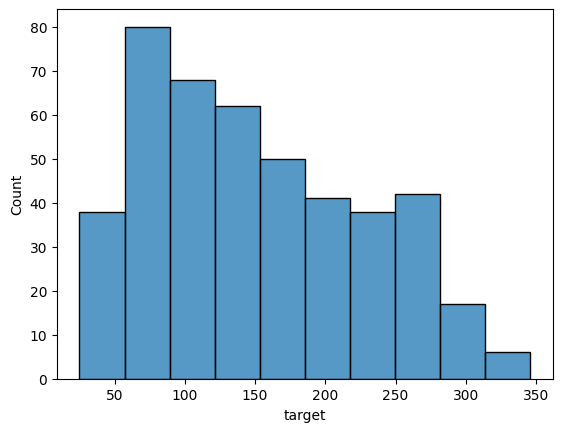

In [42]:
sns.histplot(df['target'])

In [43]:
X = df.drop('target', axis=1)
y = df['target']

In [44]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

In [45]:
scaler = StandardScaler()
X_treino_padrao = scaler.fit_transform(X_treino)
X_teste_padrao = scaler.transform(X_teste)

# Análise Matemática

Dada a matriz de atributos de treinamento $X \in \mathbb{R}^{m \times n}$ e o vetor de respostas $y \in \mathbb{R}^m$, a função objetivo da Regressão Linear com regularização Ridge é dada por:   $$f(\beta) = \frac{1}{2m} \Vert{}X\beta - y\Vert{}_2^2 + \frac{\lambda}{2} \Vert{}\beta\Vert{}_2^2$$   
Podemos expandir a norma $L_2$ usando a notação matricial $v^T v = \Vert{}v\Vert{}_2^2$:$$f(\beta) = \frac{1}{2m} (X\beta - y)^T (X\beta - y) + \frac{\lambda}{2} \beta^T \beta$$
Desenvolvendo o produto do primeiro termo:$$f(\beta) = \frac{1}{2m} \left( \beta^T X^T X \beta - 2 y^T X \beta + y^T y \right) + \frac{\lambda}{2} \beta^T \beta$$

a) Gradiente da Função Objetivo $\nabla f(\beta)$

Para calcular o gradiente em relação ao vetor de parâmetros $\beta$, aplicamos as regras de derivação matricial:



*   $\nabla_\beta (\beta^T A \beta) = 2 A \beta$ (para matrizes simétricas $A$, como $X^T X$)
*   $\nabla_\beta (a^T \beta) = a$
*   $\nabla_\beta (y^T y) = 0$


Derivando cada termo de $f(\beta)$:

$$\nabla f(\beta) = \frac{1}{2m} \left( 2 X^T X \beta - 2 X^T y \right) + \frac{\lambda}{2} (2 \beta)$$

Simplificando os fatores $2$:$$\nabla f(\beta) = \frac{1}{m} X^T (X\beta - y) + \lambda \beta$$

b) Matriz Hessiana $\nabla^2 f(\beta)$

A matriz Hessiana é a derivada do gradiente em relação a $\beta^T$:

$$\nabla^2 f(\beta) = \nabla_\beta \left( \frac{1}{m} X^T X \beta - \frac{1}{m} X^T y + \lambda \beta \right)$$Como a expressão é linear em relação a $\beta$, os termos constantes somem e obtemos:$$\nabla^2 f(\beta) = \frac{1}{m} X^T X + \lambda I_n$$
(onde $I_n$ é a matriz identidade de dimensão $n \times n$).

c) Justificativa da Convexidade

Uma função duas vezes diferenciável é estritamente convexa se sua matriz Hessiana for definida positiva ($\nabla^2 f(\beta) \succ 0$) para todo $\beta$.

1.   A matriz $X^T X$ é sempre semidefinida positiva ($X^T X \succeq 0$), pois para qualquer vetor $v \neq 0$:

$$v^T (X^T X) v = (Xv)^T (Xv) = \Vert{}Xv\Vert{}_2^2 \ge 0$$

2.   Para $\lambda > 0$, o termo de regularização $\lambda I_n$ adiciona $\lambda$ a todos os autovalores de $\frac{1}{m} X^T X$.
Se os autovalores de $\frac{1}{m} X^T X$ são $\mu_i \ge 0$, os autovalores da Hessiana são:$$\sigma_i = \mu_i + \lambda \ge \lambda > 0$$

Como todos os autovalores da Hessiana são estritamente positivos ($\sigma_i > 0$), a matriz Hessiana $\nabla^2 f(\beta)$ é definida positiva, o que garante que a função objetivo $f(\beta)$ é estritamente convexa.

d) Condição para Minimizador Único

Para que o problema possua um minimizador único:

*   Quando $\lambda > 0$ (como no experimento principal onde $\lambda = 0{,}01$), a matriz Hessiana $(\frac{1}{m} X^T X + \lambda I_n)$ é sempre invertível e estritamente definida positiva, garantindo que o problema possui um único ponto de mínimo global.
*   Quando $\lambda = 0$ (sem regularização), para existir um minimizador único, a matriz $X^T X$ precisa ter posto cheio ($\text{posto}(X) = n$), o que exige que o número de observações seja maior ou igual ao número de atributos ($m \ge n$) e que as colunas de $X$ sejam linearmente independentes.   
  

e) Condição de Otimalidade de $1^a$ Ordem e Sistema Linear

A condição necessária e suficiente de otimalidade de primeira ordem para uma função convexa e diferenciável é que o gradiente seja nulo no ponto ótimo $\beta^*$:

$$\nabla f(\beta^*) = 0$$Substituindo a expressão do gradiente obtida no item (a):   

$$\frac{1}{m} X^T (X\beta^* - y) + \lambda \beta^* = 0$$

Multiplicando a equação por $m$:

$$X^T X \beta^* - X^T y + m \lambda \beta^* = 0$$

Fatorando $\beta^*$, obtemos o sistema linear associado à solução ótima (conhecido como as Equações Normais regularizadas):

$$\left( X^T X + m \lambda I_n \right) \beta^* = X^T y$$

Alternativamente, dividindo tudo por $m$:

$$\left( \frac{1}{m} X^T X + \lambda I_n \right) \beta^* = \frac{1}{m} X^T y$$

# Implementação dos Métodos

In [51]:
def calcular_custo(X, y, beta, lmbda):
  X = np.asarray(X)
  y = np.asarray(y)
  m = X.shape[0]
  termo_erro = np.sum((X @ beta - y) ** 2) / (2 * m)
  termo_reg = (lmbda / 2) * np.sum(beta ** 2)
  return termo_erro + termo_reg


def calcular_gradiente(X, y, beta, lmbda):
  X = np.asarray(X)
  y = np.asarray(y)
  m = X.shape[0]
  return (1 / m) * (X.T @ (X @ beta - y)) + lmbda * beta

In [52]:
def gradiente_descida(X, y, lmbda, alpha=0.1, max_iter=1000, tol=1e-6):
  X = np.asarray(X)
  y = np.asarray(y)
  n_features = X.shape[1]
  beta = np.zeros(n_features)
  historico_custo = [calcular_custo(X, y, beta, lmbda)]

  for it in range(max_iter):
    grad = calcular_gradiente(X, y, beta, lmbda)
    beta_novo = beta - alpha * grad

    custo_novo = calcular_custo(X, y, beta_novo, lmbda)
    historico_custo.append(custo_novo)

    if np.linalg.norm(beta_novo - beta) < tol:
      break

    beta = beta_novo

  return beta, historico_custo

In [53]:
def gradiente_descida_estocastico(X, y, lmbda, alpha=0.01, epochs=100):
  X = np.asarray(X)
  y = np.asarray(y)
  m, n_features = X.shape
  beta = np.zeros(n_features)
  historico_custo = [calcular_custo(X, y, beta, lmbda)]

  for epoch in range(epochs):
    indices = np.random.permutation(m)
    X_shuffled = X[indices]
    y_shuffled = y[indices]

    for i in range(m):
      x_i = X_shuffled[i : i + 1]
      y_i = y_shuffled[i : i + 1]

      grad_i = x_i.T @ (x_i @ beta - y_i) + lmbda * beta
      beta = beta - alpha * grad_i

    custo_epoca = calcular_custo(X, y, beta, lmbda)
    historico_custo.append(custo_epoca)

  return beta, historico_custo

In [54]:
def metodo_newton(X, y, lmbda, max_iter=10):
  X = np.asarray(X)
  y = np.asarray(y)
  m, n_features = X.shape
  beta = np.zeros(n_features)
  historico_custo = [calcular_custo(X, y, beta, lmbda)]

  Hessiana = (X.T @ X) / m + lmbda * np.eye(n_features)

  for it in range(max_iter):
    grad = calcular_gradiente(X, y, beta, lmbda)
    delta_beta = np.linalg.solve(Hessiana, grad)

    beta_novo = beta - delta_beta
    historico_custo.append(calcular_custo(X, y, beta_novo, lmbda))

    if np.linalg.norm(beta_novo - beta) < 1e-6:
      break

    beta = beta_novo

  return beta, historico_custo

In [56]:
y_treino_mean = np.mean(y_treino)
y_treino_centralizado = y_treino - y_treino_mean

# Configurações globais dos experimentos
lmbda = 0.01

# --- Experimento 1: Execução dos Métodos ---

# 1. Gradiente de Descida (GD)
t0 = time.time()
beta_gd, hist_gd = gradiente_descida(
    X_treino_padrao, y_treino_centralizado, lmbda=lmbda, alpha=0.1, max_iter=1000
)
tempo_gd = time.time() - t0

# 2. Gradiente de Descida Estocástico (SGD)
t0 = time.time()
beta_sgd, hist_sgd = gradiente_descida_estocastico(
    X_treino_padrao,
    y_treino_centralizado,
    lmbda=lmbda,
    alpha=0.01,
    epochs=100,
)
tempo_sgd = time.time() - t0

# 3. Método de Newton
t0 = time.time()
beta_newton, hist_newton = metodo_newton(
    X_treino_padrao, y_treino_centralizado, lmbda=lmbda, max_iter=10
)
tempo_newton = time.time() - t0


# --- Experimento 2: Métricas de Avaliação no Teste ---


def calcular_metricas(X_teste_padrao, y_teste_original, beta, y_treino_mean):
    # Predição na escala padronizada + recuperação da média do treino
    y_pred = X_teste_padrao @ beta + y_treino_mean

    # Cálculo do MSE
    mse = np.mean((y_teste_original - y_pred) ** 2)

    # Cálculo do R²
    ss_res = np.sum((y_teste_original - y_pred) ** 2)
    ss_tot = np.sum((y_teste_original - np.mean(y_teste_original)) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    return mse, r2


mse_gd, r2_gd = calcular_metricas(
    X_teste_padrao, y_teste, beta_gd, y_treino_mean
)
mse_sgd, r2_sgd = calcular_metricas(
    X_teste_padrao, y_teste, beta_sgd, y_treino_mean
)
mse_newton, r2_newton = calcular_metricas(
    X_teste_padrao, y_teste, beta_newton, y_treino_mean
)

# Tabela Comparativa de Resultados
tabela_resultados = pd.DataFrame(
    {
        'Método': ['GD', 'SGD', 'Newton'],
        'Iterações/Épocas': [
            len(hist_gd) - 1,
            len(hist_sgd) - 1,
            len(hist_newton) - 1,
        ],
        'Tempo (s)': [tempo_gd, tempo_sgd, tempo_newton],
        'f(beta) final': [
            hist_gd[-1],
            hist_sgd[-1],
            hist_newton[-1],
        ],
        'MSE teste': [mse_gd, mse_sgd, mse_newton],
        'R² teste': [r2_gd, r2_sgd, r2_newton],
    }
)

print(tabela_resultados.to_string(index=False))



Método  Iterações/Épocas  Tempo (s)  f(beta) final   MSE teste  R² teste
    GD              1000   0.161984    1451.156817 2883.186210  0.455813
   SGD               100   1.490608    1482.516144 2965.690739  0.440241
Newton                 2   0.000874    1450.996084 2883.885512  0.455681


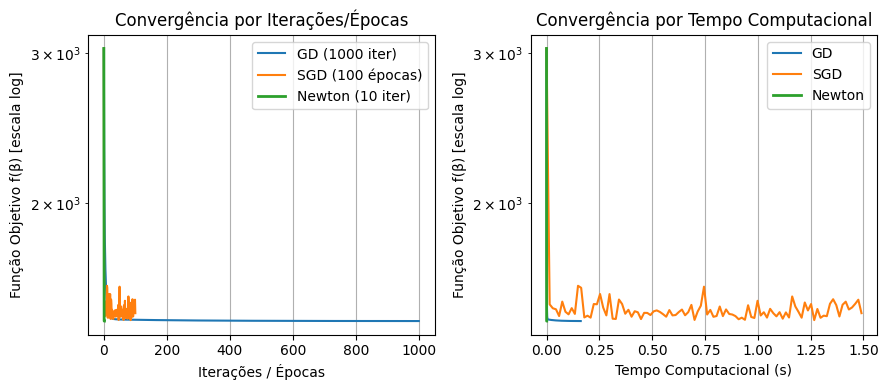

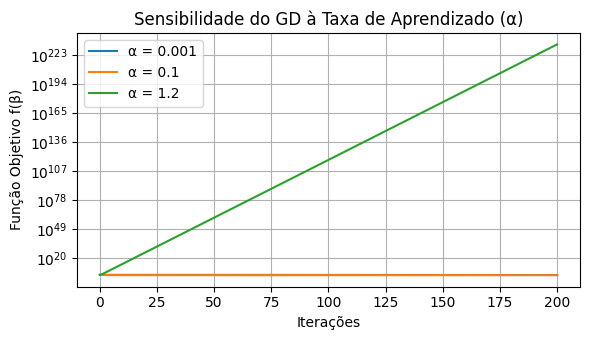

In [57]:
# --- Gráficos de Convergência (Experimento 1) ---
plt.figure(figsize=(9, 4))  # Reduzido de (12, 5) para um tamanho mais compacto

# Gráfico por Iterações/Épocas
plt.subplot(1, 2, 1)
plt.plot(hist_gd, label="GD (1000 iter)")
plt.plot(hist_sgd, label="SGD (100 épocas)")
plt.plot(hist_newton, label="Newton (10 iter)", linewidth=2)
plt.yscale("log")
plt.xlabel("Iterações / Épocas")
plt.ylabel("Função Objetivo f(β) [escala log]")
plt.title("Convergência por Iterações/Épocas")
plt.legend()
plt.grid(True)

# Gráfico por Tempo Computacional
tempo_eixo_gd = np.linspace(0, tempo_gd, len(hist_gd))
tempo_eixo_sgd = np.linspace(0, tempo_sgd, len(hist_sgd))
tempo_eixo_newton = np.linspace(0, tempo_newton, len(hist_newton))

plt.subplot(1, 2, 2)
plt.plot(tempo_eixo_gd, hist_gd, label="GD")
plt.plot(tempo_eixo_sgd, hist_sgd, label="SGD")
plt.plot(tempo_eixo_newton, hist_newton, label="Newton", linewidth=2)
plt.yscale("log")
plt.xlabel("Tempo Computacional (s)")
plt.ylabel("Função Objetivo f(β) [escala log]")
plt.title("Convergência por Tempo Computacional")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# --- Experimento 3: Sensibilidade à Taxa de Aprendizado no GD ---
plt.figure(figsize=(6, 3.5))  # Reduzido de (8, 5) para ficar mais enxuto
taxas_alpha = [0.001, 0.1, 1.2]

for alpha in taxas_alpha:
  _, hist = gradiente_descida(
      X_treino_padrao, y_treino_centralizado, lmbda=lmbda, alpha=alpha, max_iter=200
  )
  plt.plot(hist, label=f"α = {alpha}")

plt.yscale("log")
plt.xlabel("Iterações")
plt.ylabel("Função Objetivo f(β)")
plt.title("Sensibilidade do GD à Taxa de Aprendizado (α)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Análise e Discussão dos Resultados

Questão 1. Os três métodos encontraram soluções com valores semelhantes da função objetivo? Explique possíveis diferenças.

Sim, todos chegaram a valores finais muito parecidos. As pequenas diferenças ocorrem porque o GD e o Newton utilizam todos os dados de forma global, enquanto o SGD atualiza os parâmetros com base em amostras individuais, introduzindo uma pequena variação que o faz flutuar perto do ponto ótimo.

Questão 2. Qual método apresentou convergência mais rápida em termos de iterações? E em termos de tempo computacional?

O Método de Newton foi o mais rápido em ambos os critérios. Por utilizar a matriz Hessiana, ele consegue mapear a curvatura exata do problema e atingir o mínimo em pouquíssimas iterações.

Questão 3. Como a escolha da taxa de aprendizado influenciou o comportamento do Gradiente de Descida?

Valores muito baixos deixam a convergência lenta. Já uma taxa de aprendizado excessivamente alta faz com que o algoritmo dê saltos exagerados, afastando-se do objetivo e fazendo o custo "explodir" para valores massivos.

Questão 4. Por que o Gradiente de Descida Estocástico pode apresentar oscilações durante o treinamento?

Porque o SGD calcula as atualizações dividindo o processo em partes ou amostras isoladas a cada passo. Isso introduz ruído e faz com que o algoritmo ziguezagueie em vez de seguir uma linha reta até o fundo.

Questão 5. Qual foi o comportamento observado para o método de Newton? Como esse comportamento pode ser explicado pela estrutura quadrática do problema?

O método apresentou uma queda imediata logo no início. Como o problema da regressão Ridge é estritamente quadrático (formato de parábola perfeita), o passo de Newton calcula o ponto exato de mínimo de uma só vez.

Questão 6. Os modelos treinados pelos diferentes algoritmos apresentaram desempenho preditivo semelhante? O que isso indica sobre a relação entre otimização e generalização?

Sim, as métricas no conjunto de teste (MSE e $R^2$) foram praticamente iguais. Isso mostra que, desde que o algoritmo encontre a região ótima, a capacidade de generalização do modelo depende muito mais da formulação matemática e da regularização escolhida do que do método numérico utilizado para treinar.